I will try to fit the simulation data to extract T1, T2 and the rabi frequency.
The rabi frequency is the roation speed of the transition between the different states. In a 2 level system at ressonance $$P_1(t) = \sin^2\!\left(\frac{\Omega_R\, t}{2}\right)$$ 
where the rabi frequency is $$\Omega_R = \Omega_0\, |A_{01}|$$
However even without dissipation this will not be a good estimation since the system is a 3 level system so the probability P1 is never completely 1 and evnen worse with dissipation because it will continue to fall

From experiments I know the drive frequency w and can with spectroscopy determine E_c and E_j which also gives me A, however I do not know T1 T2 omega or the rabi frequency
$$\Omega_0 = \frac{\Omega_R}{n_{01}}$$
I can controle the amplitude I just dont know it exact for small amplitudes it is almost a 2 level system with leakage.
without leakage $$P_1(t) = \sin^2\!\left(\frac{\Omega_R\, t}{2} \right) $$

$$\sin^2\!\left(\frac{\Omega_R t}{2}\right) = \frac12 - \frac12\cos(\Omega_R t)$$
and the dissipation adds a an exponential dampening factor on the oscilating term
$$P_1(t) = \frac12 - \frac12\, e^{-\gamma t}\cos(\Omega_R t)$$

In [1]:
import numpy as np
from scipy.sparse import linalg as sla
import matplotlib.pyplot as plt
from myfunctions import powell_search, gaussian, rk4solve
from part2 import H_number, H_time
from part3 import Lindblad

In [28]:
#create the hamilton and the initial density matrix
##
E_c = 2*np.pi * 0.25   # rad/ns is E_c/h 0.25 GHz 50x smaller than E_j
E_j = 2*np.pi * 12.5   # rad/ns # same as before is E_j/h 12.5 GHz
N=np.arange(-10,11,1) # the number of Cooper pairs from -10 to 10
t1, t2= 200, 150 # the relaxation and dephasing times in ns
gamma= 1.4 * np.array([1/t1,2 * (1/t2 - 1 / (2*t1))]) # the dissipation rates for the two levels
T1 = np.array([[0,1,0],[0,0,np.sqrt(2)],[0,0,0]],dtype=complex) # the lowering operator a on 3 levels
T2 = np.diag([0,1,2]) # adagger a 
T = np.array([T1,T2]) # the array of the two operators
T_g = 500 # gate time in ns
dT_g=0.005 # stepsize
rho0 = np.array([[1,0,0],[0,0,0],[0,0,0]],dtype=complex) # the initial density matrix
mu = T_g/2 # the amplitude is at its maximum at half of the gate time
sigma = T_g/6 # make sure it is close to zero in the start and end

H_num = H_number(N, E_c, E_j) # the hamiltonian in n basis
E,U= sla.eigsh(H_num, k=3, which='SA') # the eigenvalues and eigenvectors in n basis
H_0= np.diag(E,0)- E[0] * np.eye(3) # the diagonal matrix of the eigenvalues with the ground state energy subtracted so that the ground state energy is zero.
w = E[1]-E[0]  # Taken from part 4.
A= U.T @ np.diag(N) @ U #the coupling term between the different states
omega= E_c/20# the amplitude of the drive must be smaller than E_c  # the amplitude of the drive in rad/ns taken from part 4
# this guess for omega0 is based on a two level system and does not take into account the third level. The optimal omega0 will be found using the powell_search function and considering the third level. 


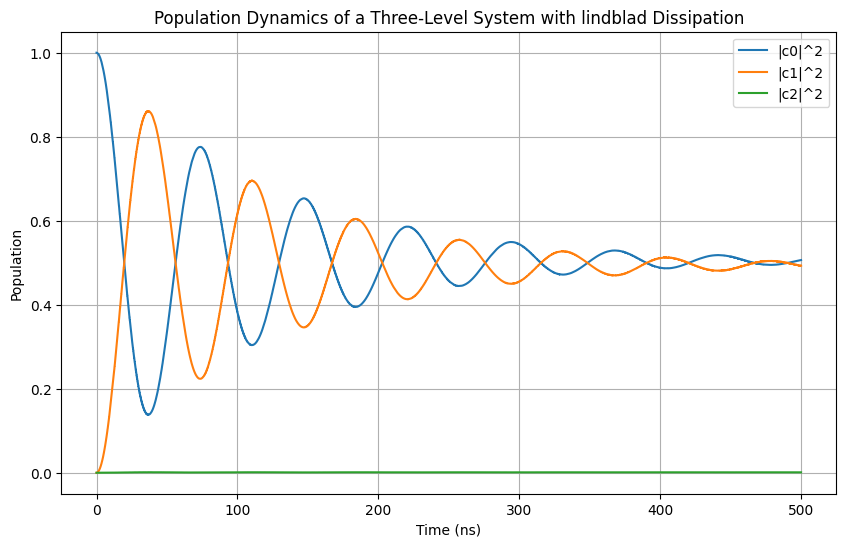

In [29]:
def f(t,rho): # the function that will be used in the RK4 method to solve the Lindblad equatio
    H = H_time(t,H_0,A,omega,w)
    return Lindblad(T, rho, H, gamma)
t_L,C_L = rk4solve(f, rho0, 0, dT_g, T_g)
plt.figure(figsize=(10,6))
plt.plot(t_L, C_L[:, 0, 0].real, label='|c0|^2')
plt.plot(t_L, C_L[:, 1, 1].real, label='|c1|^2')
plt.plot(t_L, C_L[:, 2, 2].real, label='|c2|^2')
plt.xlabel('Time (ns)')
plt.ylabel('Population')
plt.title('Population Dynamics of a Three-Level System with lindblad Dissipation')
plt.legend()
plt.grid()

In [36]:
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
peaks, _ = find_peaks(y, prominence=0.2)            # index for peaks in the data
t_peaks = t_L[peaks]
y_peaks = y[peaks]
def model_U(t, gamma, rabi, b):
    return b - 0.5 * np.exp(-gamma * t) * np.cos(rabi * t) #The offset b is expected to be around 0.5, but it is left as a free parameter in the fit.
b_guess = 0.5
Omega_guess = 2 * np.pi / np.mean(np.diff(t_peaks)) # because the period of the oscillation is the time difference between the peaks, and the Rabi frequency is 2*pi/period. np.diff(t_peaks) gives the time difference between each pair of adjacent peaks.
gamma_guess = np.log((y_peaks[0] - b_guess) / (y_peaks[-1] - b_guess)) / (t_peaks[-1] - t_peaks[0])  # the decay rate is estimated from the logarithm of the ratio of the first and last peak heights, divided by the time difference between the first and last peaks.
p0 = [gamma_guess, Omega_guess, b_guess] # initial guess for the parameters
y= C_L[:, 1, 1].real # the population of the first excited state
p0 = [gamma_guess, Omega_guess, b_guess] # initial guess for the parameters
par, cov = curve_fit(model_U, t_L,y, p0=p0) # fit the model to the data

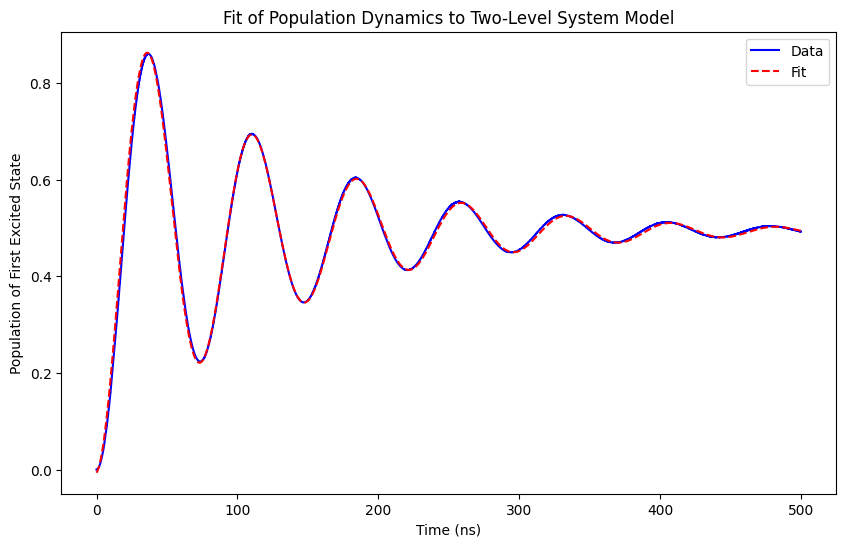

In [37]:
y_fit = model_U(t_L, *par)
plt.figure(figsize=(10,6))
plt.plot(t_L, y, label='Data', color='blue')
plt.plot(t_L, y_fit, label='Fit', color='red', linestyle='--')
plt.xlabel('Time (ns)')
plt.ylabel('Population of First Excited State')
plt.title('Fit of Population Dynamics to Two-Level System Model')
plt.legend(loc='upper right')    
plt.show()  